# Домашнее задание по теме «Базовые принципы ML и метрики регрессии»

Это первое домашнее задание на курсе по ML.

<!-- Повторим ключевые особенности, о которых стоит помнить (со многими из них ты уже сталкивался в рамках курса "Искуственный интеллект"): -->




Важно помнить:
* За каждую задачу ты получаешь баллы.
* Сумма баллов за все задания — 12.
Максимальный балл за домашнее задание — 10. Разница в 2 балла позволит выбирать задачи или решить все, но получить максимальный балл даже в случае ошибки.
* В заданиях будут подсказки, инструкции и дополнительная теория, которая поможет по-новому посмотреть на тему.
* Условия задач — это техническое задание для разработчика, которому надо точно следовать.



## Импорт библиотек

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

## Загрузка данных

In [ ]:
!gdown 13vRyN_RKtoUWtGWi0O8ZlP5Q2C0O0F9l

Downloading...
From: https://drive.google.com/uc?id=13vRyN_RKtoUWtGWi0O8ZlP5Q2C0O0F9l
To: /content/store_sharing.csv
100% 1.03M/1.03M [00:00<00:00, 14.3MB/s]


Дальше ты будешь работать с датасетом, который содержит данные по аренде велосипедов. Ниже подробно описаны его признаки.

In [ ]:
bike = pd.read_csv('/content/store_sharing.csv')
bike.head()

,timestamp,cnt,t1,t2,hum,wind_speed,weather_code,is_holiday,is_weekend,season
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0


**Признаки**

* `timestamp` — временная метка, используется для группировки данных по времени.
* `cnt` — общее количество новых аренд велосипедов (bike shares) за период между текущим и следующим `timestamp`. Обрати внимание, что это целевая переменная задачи регрессии.
* `t1` — фактическая температура воздуха (в градусах Цельсия).
* `t2` — температура «по ощущениям» (в градусах Цельсия); учитывает влияние ветра и влажности.
* `hum` — относительная влажность воздуха в процентах.
* `wind_speed` — скорость ветра (в километрах в час).
* `weather_code` — категориальный признак, описывающий погодные условия:
 * 1 — ясно;
 * 2 — рассеянная облачность / немного облаков;
 * 3 — переменная облачность (частично закрыто облаками);
 * 4 — пасмурно;
 * 7 — дождь / слабый ливень / мелкий дождь;
 * 10 — дождь с грозой;
 * 26 — снегопад;
 * 94 — туман / морозный туман.

* `is_holiday` — логический признак: 1 — праздничный день, 0 — обычный день.
* `is_weekend` — логический признак: 1 — выходной день (суббота или воскресенье), 0 — будний день.
* `season` — категориальный признак, обозначающий время года:
 * 0 — весна;
 * 1 — лето;
 * 2 — осень;
 * 3 — зима.



## Предобработка данных

Посмотрим на данные.

In [ ]:
bike.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17414 entries, 0 to 17413
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   timestamp     17414 non-null  object 
 1   cnt           17414 non-null  int64  
 2   t1            17414 non-null  float64
 3   t2            17414 non-null  float64
 4   hum           17414 non-null  float64
 5   wind_speed    17414 non-null  float64
 6   weather_code  17414 non-null  float64
 7   is_holiday    17414 non-null  float64
 8   is_weekend    17414 non-null  float64
 9   season        17414 non-null  float64
dtypes: float64(8), int64(1), object(1)
memory usage: 1.3+ MB


In [ ]:
bike.columns

Index(['timestamp', 'cnt', 't1', 't2', 'hum', 'wind_speed', 'weather_code',
       'is_holiday', 'is_weekend', 'season'],
      dtype='object')

In [ ]:
bike.describe().T

,count,mean,std,min,25%,50%,75%,max
cnt,17414.0,1143.101642,1085.108068,0.0,257.0,844.0,1671.75,7860.0
t1,17414.0,12.468091,5.571818,-1.5,8.0,12.5,16.00,34.0
t2,17414.0,11.520836,6.615145,-6.0,6.0,12.5,16.00,34.0
hum,17414.0,72.324954,14.313186,20.5,63.0,74.5,83.00,100.0
wind_speed,17414.0,15.913063,7.894570,0.0,10.0,15.0,20.50,56.5
weather_code,17414.0,2.722752,2.341163,1.0,1.0,2.0,3.00,26.0
is_holiday,17414.0,0.022051,0.146854,0.0,0.0,0.0,0.00,1.0
is_weekend,17414.0,0.285403,0.451619,0.0,0.0,0.0,1.00,1.0
season,17414.0,1.492075,1.118911,0.0,0.0,1.0,2.00,3.0


In [ ]:
# Есть ли дубли в строках

duplicate_rows = bike.duplicated().sum()
if duplicate_rows > 0:
    print("\nКоличество дублирующихся строк:", duplicate_rows)
    print("Дубли:")
    print(df[df.duplicated()])
else:
    print("\nДублирующиеся строки отсутствуют.")


Дублирующиеся строки отсутствуют.


In [ ]:
# Есть ли пропущенные значения

bike.isnull().sum()

,0
timestamp,0
cnt,0
t1,0
t2,0
hum,0
wind_speed,0
weather_code,0
is_holiday,0
is_weekend,0
season,0


Проведём небольшую предобработку для более удобной работы с данными.

In [ ]:
# Переименуем некоторые столбцы

bike.rename(columns={'cnt':'total_count', 't1':'temp', 't2':'feel_temp', 'hum':'humidity'}, inplace=True)
bike.columns

Index(['timestamp', 'total_count', 'temp', 'feel_temp', 'humidity',
       'wind_speed', 'weather_code', 'is_holiday', 'is_weekend', 'season'],
      dtype='object')

In [ ]:
# Разделим дату и время из столбца timestamp на несколько отдельных признаков, а именно:
# год, месяц, день, день недели (номер), час

bike.timestamp = pd.to_datetime(bike.timestamp)

bike['year'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.year
bike['month'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.month
bike['day'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.day
bike['day_of_week'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.dayofweek
bike['hour'] = pd.to_datetime(bike['timestamp'], format='%d/%m/%Y').dt.hour

In [ ]:
bike.head()

,timestamp,total_count,temp,feel_temp,humidity,wind_speed,weather_code,is_holiday,is_weekend,season,year,month,day,day_of_week,hour
0,2015-01-04 00:00:00,182,3.0,2.0,93.0,6.0,3.0,0.0,1.0,3.0,2015,1,4,6,0
1,2015-01-04 01:00:00,138,3.0,2.5,93.0,5.0,1.0,0.0,1.0,3.0,2015,1,4,6,1
2,2015-01-04 02:00:00,134,2.5,2.5,96.5,0.0,1.0,0.0,1.0,3.0,2015,1,4,6,2
3,2015-01-04 03:00:00,72,2.0,2.0,100.0,0.0,1.0,0.0,1.0,3.0,2015,1,4,6,3
4,2015-01-04 04:00:00,47,2.0,0.0,93.0,6.5,1.0,0.0,1.0,3.0,2015,1,4,6,4


Дальше ты будешь строить графики и делать по ним выводы. К первым задачам вывод уже написан — это поможет тебе понять, как их писать.

## Задача 1 [1 балл]

Для начала построй два графика.

1. Построй гистограмму распределения общего количества арендованных велосипедов (`total_count`) с наложенной линией KDE (Kernel Density Estimate), чтобы визуально оценить форму распределения данных. Оформи график с понятным заголовком и подписями осей. **[0,5 балла]**
  > **Примечание.** К этому графику вывод уже написан — ты найдёшь его ниже.
2. Преобразуй столбец `timestamp` к формату даты без времени (`date`). Объедини данные о прокате велосипедов по дням, посчитав суммарное количество арендованных велосипедов за каждый день. Построй линейный график с динамикой суточного числа аренд (`total_count`) во времени. Дополни график заголовком, подписью оси $Y$, а также поверни подписи по оси $X$ на 90 градусов для читаемости. **[0,5 балла]**

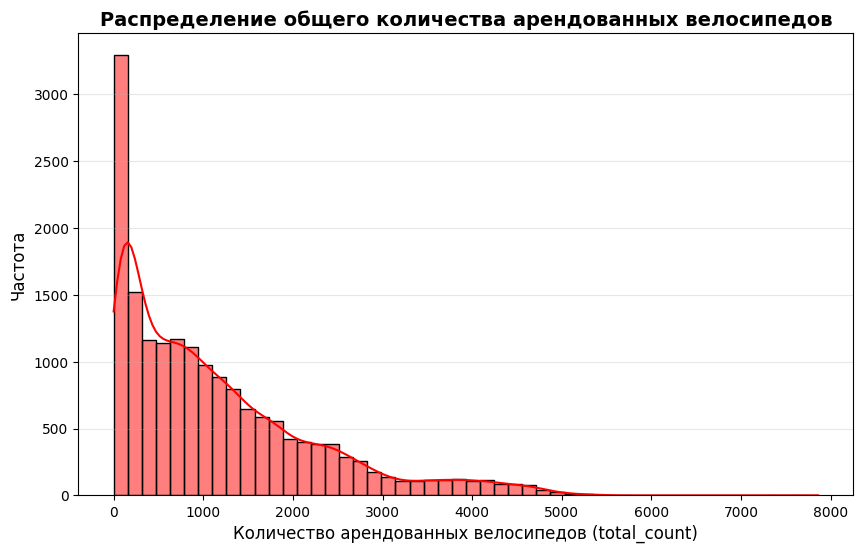

In [ ]:
# Напиши здесь код для гистограммы распределения
plt.figure(figsize=(10, 6))

sns.histplot(data=bike, x='total_count', kde=True, bins=50, color='red')

plt.title('Распределение общего количества арендованных велосипедов', fontsize=14, fontweight='bold')
plt.xlabel('Количество арендованных велосипедов (total_count)', fontsize=12)
plt.ylabel('Частота', fontsize=12)

plt.grid(axis='y', alpha=0.3)
plt.show()


**Вывод**

Гистограмма показывает распределение количества аренд велосипедов. Видна смещённость вправо. У распределения выраженная правосторонняя асимметрия — большинство значений приходится на малые значения с заметным пиком в области очень низких показателей. Это говорит о том, что чаще всего велосипеды арендуют в небольшом количестве, а случаи массового проката встречаются значительно реже.

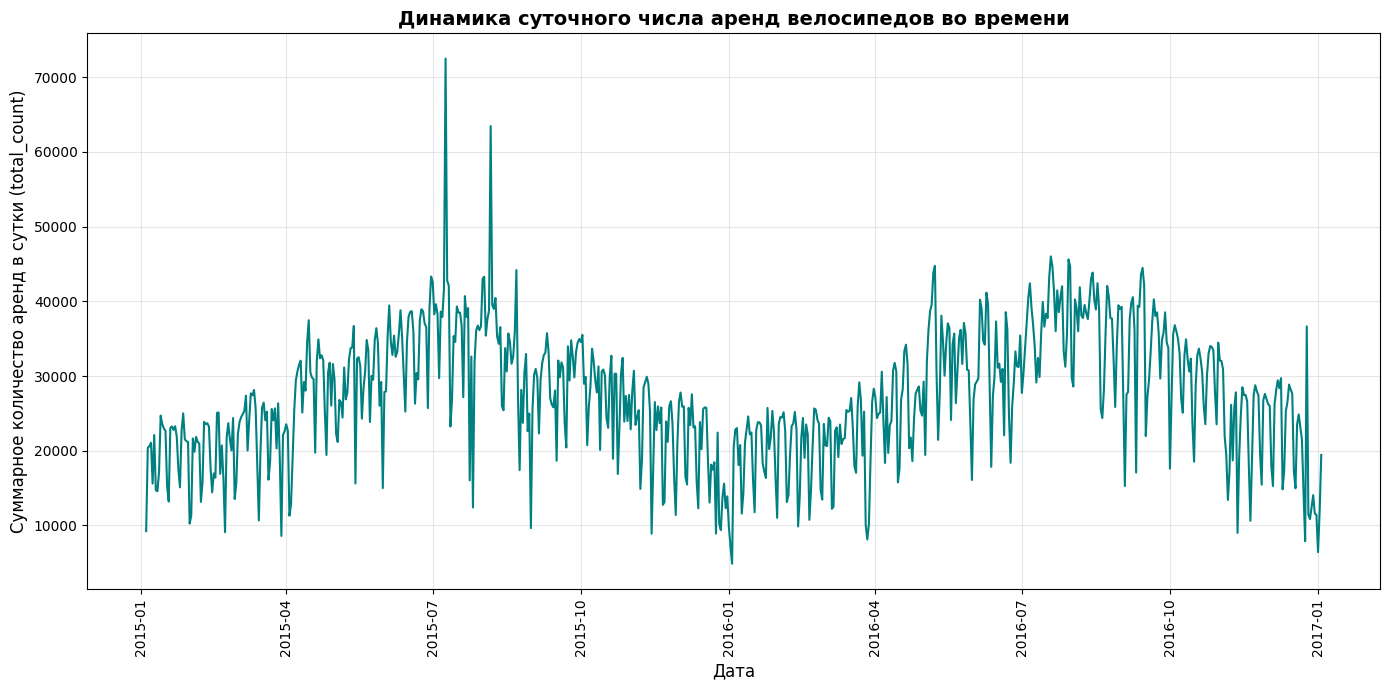

In [ ]:
# Напиши здесь код для линейного графика с динамикой total_count
bike['date'] = bike['timestamp'].dt.date

daily_bike = bike.groupby('date')['total_count'].sum().reset_index()

plt.figure(figsize=(14, 7))
plt.plot(daily_bike['date'], daily_bike['total_count'], color='teal', linewidth=1.5)

plt.title('Динамика суточного числа аренд велосипедов во времени', fontsize=14, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('Суммарное количество аренд в сутки (total_count)', fontsize=12)

plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Задача 2 [3 балла]

Продолжи и построй более сложные графики.

###Задача 2.1 [1 балл]



1. Сгруппируй данные по столбцу `month` и посчитай суммарное количество аренд велосипедов по каждому месяцу.
2. Построй линейный график с зависимостью общего количества аренд от месяца.
3. Реализуй форматирование оси $Y$ так, чтобы значения отображались в тысячах.
4. Добавь подписи осей и заголовок графика.
5. Отобрази итоговый график.

Напиши вывод о сезонности аренды велосипедов по полученному графику.



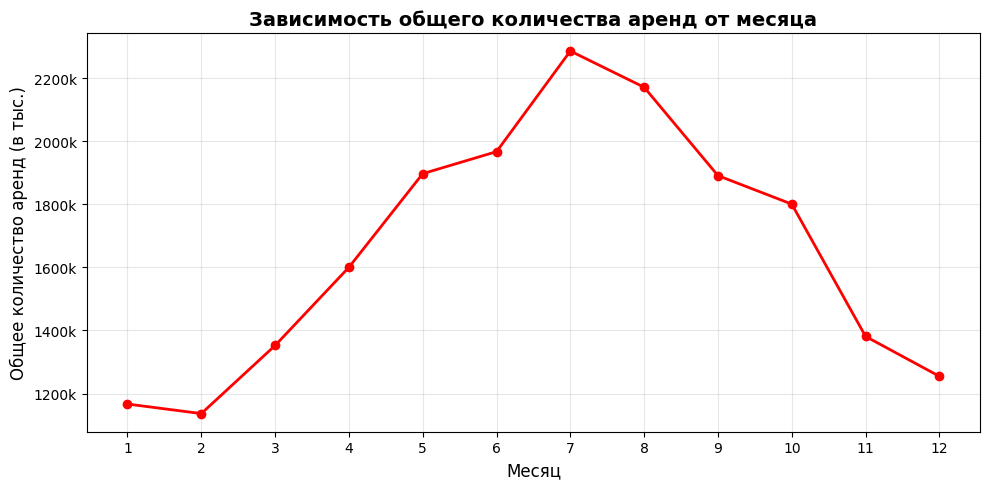

In [ ]:
# Напиши здесь код для линейного графика с зависимостью общего количества аренд от месяца
monthly_bike = bike.groupby('month')['total_count'].sum().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(monthly_bike['month'], monthly_bike['total_count'], marker='o', color='red', linewidth=2)

plt.title('Зависимость общего количества аренд от месяца', fontsize=14, fontweight='bold')
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Общее количество аренд (в тыс.)', fontsize=12)

plt.xticks(range(1, 13))

labels = [f'{int(x/1000)}k' for x in plt.gca().get_yticks()]
plt.gca().set_yticklabels(labels)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Твой вывод**

График наглядно демонстрирует ярко выраженную сезонность спроса -  количество аренд начинает уверенно расти весной (марта-май), достигает своего пика в летние месяцы (июнь–август) и начинает постепенно снижаться осенью. Минимальный спрос ожидаемо приходится на зимний период (декабрь–февраль).

Это подтверждает, что ключевым фактором популярности велопроката являются благоприятные погодные условия.

###Задача 2.2 [1 балл]

1. Сгруппируй данные по сезонам и рассчитай для каждого сезона максимальное, минимальное, среднее и суммарное количество аренд велосипедов с помощью функции `agg`.
2. Реализуй столбчатую диаграмму (barplot), которая показывает суммарное количество аренд велосипедов по сезонам. Используй значения суммы, полученные на предыдущем шаге.
3. Используй читаемые подписи сезонов вместо числовых значений (обрати внимание, как они закодированы в датасете).
4. Настрой размер графика (`figsize=(8, 4)`) и выбери цветовую палитру (`viridis`).
5. Добавь подписи осей `Season` и `Bike Shares` и заголовок графика `Total Bike Shares by Season`.
6. Отформатируй метки оси $Y$ так, чтобы значения были приведены в тысячах.
7. Выведи построенный график.

Напиши вывод: в какие сезоны суммарное количество аренд больше, а в какие — меньше.

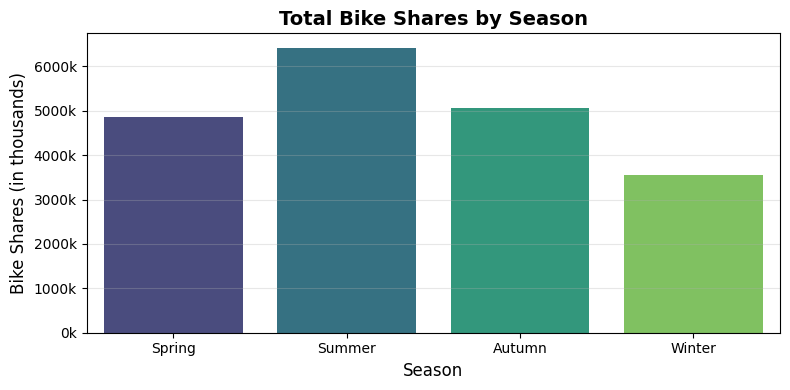

In [ ]:
# Напиши здесь код для столбчатой диаграммы, показывающей общее количество аренд велосипедов по сезонам

season_agg = bike.groupby('season')['total_count'].agg(['min', 'max', 'mean', 'sum']).reset_index()

season_mapping = {0: 'Spring', 1: 'Summer', 2: 'Autumn', 3: 'Winter'}
season_agg['season_name'] = season_agg['season'].map(season_mapping)

plt.figure(figsize=(8, 4))
sns.barplot(data=season_agg, x='season_name', y='sum', palette='viridis')

plt.title('Total Bike Shares by Season', fontsize=14, fontweight='bold')
plt.xlabel('Season', fontsize=12)
plt.ylabel('Bike Shares (in thousands)', fontsize=12)

labels = [f'{int(x/1000)}k' for x in plt.gca().get_yticks()]
plt.gca().set_yticklabels(labels)

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Твой вывод**

Наибольшее суммарное количество аренд велосипедов наблюдается в летний сезон (Summer), на втором месте находится осень (Autumn), а на третьем — весна (Spring). Наименьшее количество поездок зафиксировано зимой (Winter).

Разрыв между пиковым летним и минимальным зимним сезоном является весьма существенным, что полностью подтверждает выводы из предыдущего шага.

###Задача 2.3 [1 балл]

1. Сгруппируй датафрейм `bike` по признакам `season` и `day_of_week`. Вычисли среднее значение столбца `total_count` для каждой группы и сбрось индексы.
2. Построй `pointplot`, где по оси $X$ — `day_of_week`, по оси $Y$ — `total_count`. Цветом (`hue`) обозначь сезоны, заменив числовые коды на строковые метки (как и в задаче выше).
3. Задай подписи осей и заголовок графика.
4. Обнови подписи оси $X$ так, чтобы вместо чисел отображались названия дней недели.
5. Добавь легенду графика.
6. Используй `plt.tight_layout()` для корректного размещения элементов, а затем выведи график.

Дополнительно напиши вывод по полученному графику. Можешь использовать шаблон:

* пиковая нагрузка наблюдается ... особенно с ... по ...;
* на выходных отмечается ... по сравнению с рабочей неделей;
* на графике наблюдаются сезонные колебания, они ... нашу гипотезу, обозначенную выше;
* характер поведения данных ... во все сезоны.




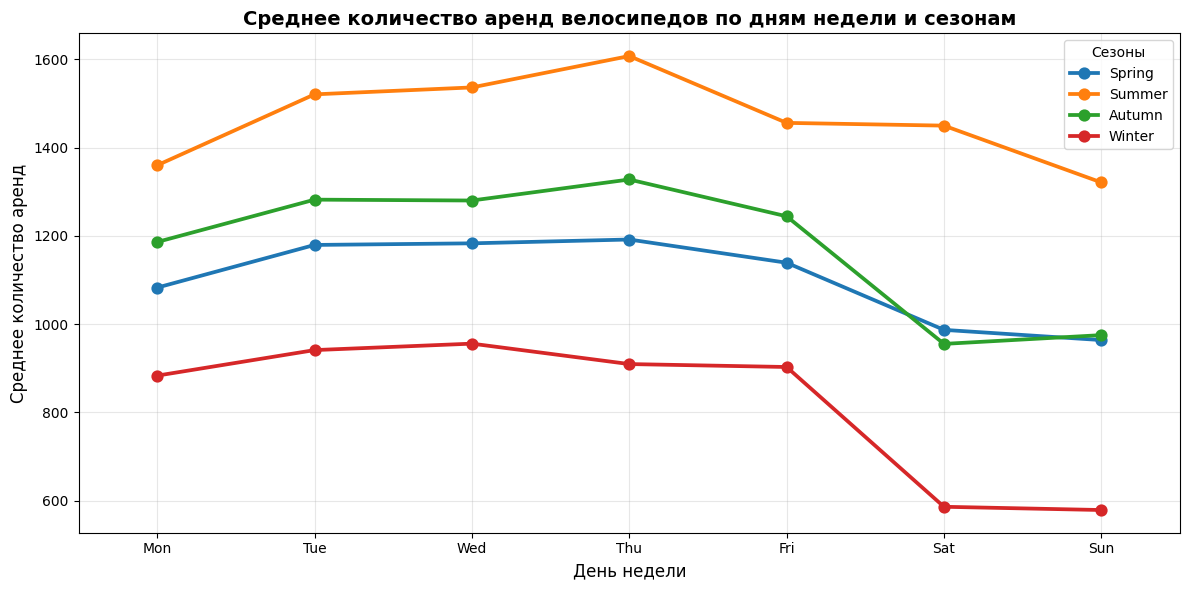

In [ ]:
# Напиши код здесь для pointplot со средним количеством аренд по дням недели по сезонам

weekly_season = bike.groupby(['season', 'day_of_week'])['total_count'].mean().reset_index()

weekly_season['Season'] = weekly_season['season'].map({0: 'Spring', 1: 'Summer', 2: 'Autumn', 3: 'Winter'})

plt.figure(figsize=(12, 6))
sns.pointplot(data=weekly_season, x='day_of_week', y='total_count', hue='Season', markers='o', linestyles='-')

plt.title('Среднее количество аренд велосипедов по дням недели и сезонам', fontsize=14, fontweight='bold')
plt.xlabel('День недели', fontsize=12)
plt.ylabel('Среднее количество аренд', fontsize=12)

days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
plt.xticks(range(7), days)

plt.legend(title='Сезоны')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Твой вывод**

- Пиковая нагрузка наблюдается в будние дни, особенно с понедельника по пятницу (в середине рабочей недели спрос наиболее стабилен).
- На выходных отмечается заметный спад среднего количества аренд по сравнению с рабочей неделей, что может указывать на то, что велосипеды чаще используют как регулярный транспорт для поездок на работу или учебу, а не только для отдыха.
- На графике наблюдаются сезонные колебания, они полностью подтверждают нашу гипотезу, обозначенную выше (лето лидирует, зима — отстаёт).
- Характер поведения данных остается схожим во все сезоны: графики всех четырех сезонов синхронно повторяют одну и ту же форму с просадкой на выходных.

## Задача 3 [2 балла]

###Задача 3.1 [1 балл]

1. Построй линейный график, который показывает распределение количества поездок на велосипедах в зависимости от времени суток.
2. Используй признак `is_weekend` в качестве группирующего фактора, чтобы сравнить популярность велопроката в будние и выходные дни.
3. Настрой легенду так, чтобы линии были подписаны как `No` (будний день) и `Yes` (выходной день).
4. Добавь заголовок графика.
5. Отобрази график с использованием функции `plt.tight_layout()` для корректного размещения элементов.
6. Напиши вывод. Опиши наблюдения по утренним и вечерним пикам, разницу между рабочими днями и выходными.



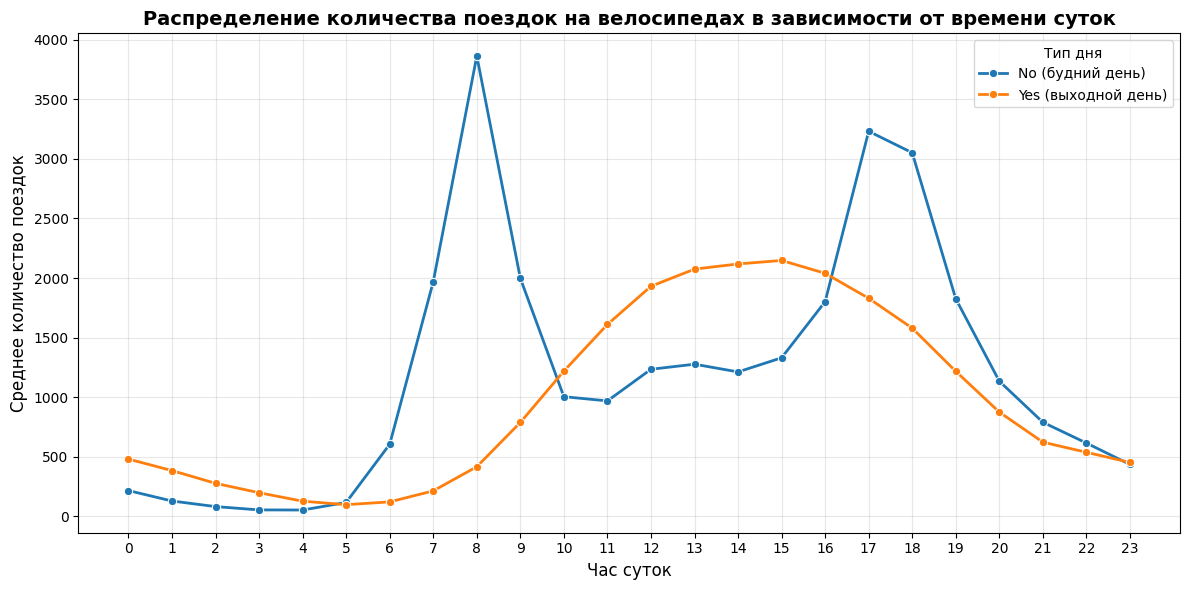

In [ ]:
# Напиши здесь код для линейного графика, показывающего распределение количества поездок на велосипедах в зависимости от часа суток по будням и выходным дням

hourly_weekend = bike.groupby(['hour', 'is_weekend'])['total_count'].mean().reset_index()

hourly_weekend['Тип дня'] = hourly_weekend['is_weekend'].map({0: 'No (будний день)', 1: 'Yes (выходной день)'})

plt.figure(figsize=(12, 6))
sns.lineplot(data=hourly_weekend, x='hour', y='total_count', hue='Тип дня', marker='o', linewidth=2)

plt.title('Распределение количества поездок на велосипедах в зависимости от времени суток', fontsize=14, fontweight='bold')
plt.xlabel('Час суток', fontsize=12)
plt.ylabel('Среднее количество поездок', fontsize=12)

plt.xticks(range(0, 24))

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Твой вывод**

График наглядно демонстрирует принципиальное различие в паттернах поведения пользователей в будни и выходные дни:
- В будние дни (No) отчетливо видны два выраженных пика активности: утренний (8:00) и вечерний (17:00–18:00). Это классические часы пик, подтверждающие, что в рабочие дни велосипеды служат заменой общественному транспорту или автомобилю для поездок на работу и учебу.
- В выходные дни (Yes) характер распределения плавный, куполообразный. Активность постепенно нарастает с утра, достигает своего максимума в середине дня (с 12:00 до 16:00) и плавно спадает к вечеру. Это говорит о том, что в выходные велосипеды арендуют преимущественно для отдыха и прогулок.





###Задача 3.2 [1 балл]
1. Создай график с двумя круговыми диаграммами, расположенными в одну строку.
2. Для первой диаграммы отобрази распределение количества поездок по признаку `is_holiday` с метками `No` и `Yes`. Укажи процентное соотношение каждого значения, используй цвета `lightblue` и `orange`. Установи начальный угол (`startangle`) на 90 градусов и добавь заголовок.
3. Для второй диаграммы отобрази распределение количества поездок по признаку `is_weekend` с метками `Weekday` и `Weekend`. Укажи процентное соотношение каждого значения, используй те же цвета и начальный угол, добавь заголовок.
4. Обеспечь компактное расположение графиков с помощью tight_layout.
5. Отобрази полученный график.
6. Опиши обе круговые диаграммы. Какие выводы  можно сделать по каждой из них?


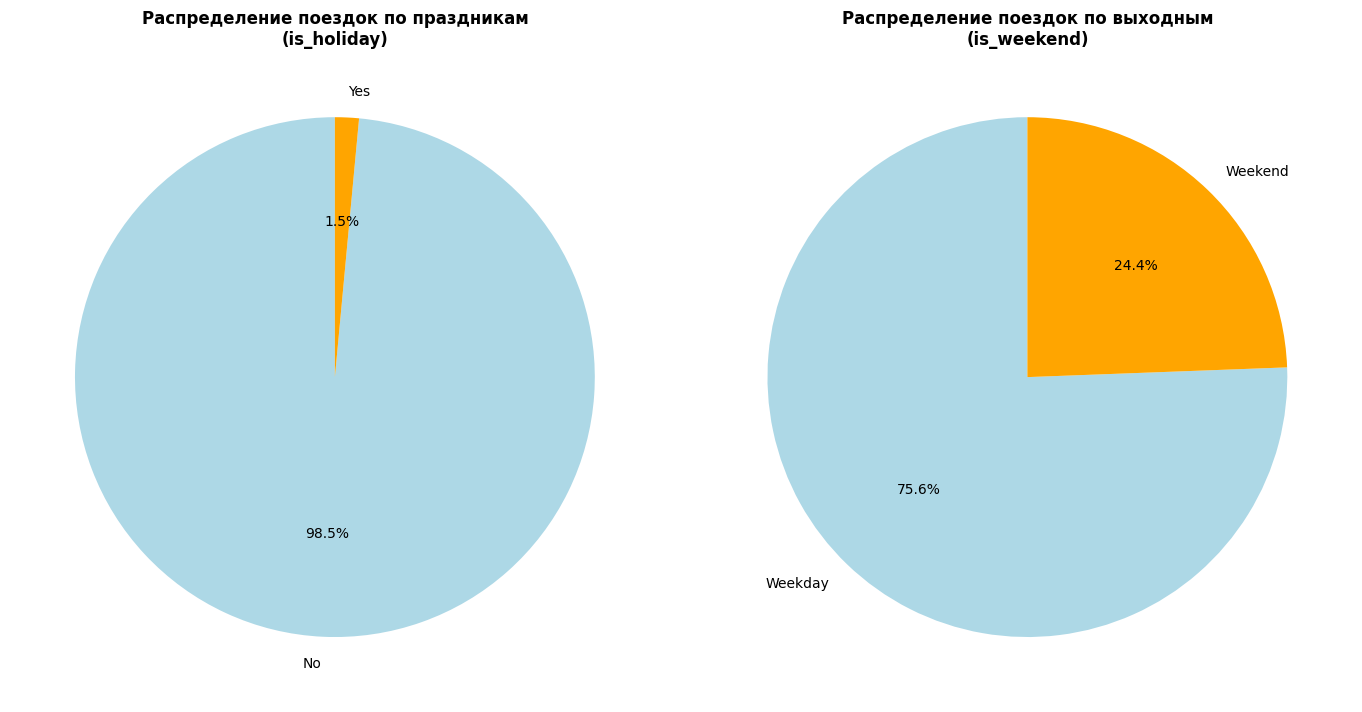

In [ ]:
# Напиши здесь код для двух круговых диаграмм
holiday_counts = bike.groupby('is_holiday')['total_count'].sum()
weekend_counts = bike.groupby('is_weekend')['total_count'].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].pie(holiday_counts,
            labels=['No', 'Yes'],
            autopct='%1.1f%%',
            colors=['lightblue', 'orange'],
            startangle=90)
axes[0].set_title('Распределение поездок по праздникам\n(is_holiday)', fontsize=12, fontweight='bold')

axes[1].pie(weekend_counts,
            labels=['Weekday', 'Weekend'],
            autopct='%1.1f%%',
            colors=['lightblue', 'orange'],
            startangle=90)
axes[1].set_title('Распределение поездок по выходным\n(is_weekend)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

**Твой вывод**

- Диаграмма is_holiday (Праздники): Абсолютное большинство всех поездок (более 98%) совершается в обычные, не праздничные дни. Праздники занимают лишь крошечную долю в общем объеме данных. Это связано исключительно с календарем - праздничных дней в году мало, поэтому их суммарный вклад в годовой прокат невелик.

- Диаграмма is_weekend (Выходные): На будние дни (Weekday) приходится большая часть всех совершенных поездок (~75%), в то время как на выходные (Weekend) остается меньшая часть (порядка 25%). Несмотря на то, что в выходные люди активно катаются днем (как показал график 3.1), суммарно будни забирают лидерство за счет того, что рабочих дней в неделе 5, а выходных всего 2, а также благодаря мощным пиковым нагрузкам в утренние и вечерние часы.

## Задача 4 [3 балла]

###Задача 4.1 **[1 балл]**

1. Построй два `scatter plot` на одной фигуре с двумя строками и одним столбцом, `figsize=(15, 10)`.
2. На первом графике отобрази зависимость количества поездок на велосипедах (`total_count`) от температуры (`temp`). Обязательно добавь заголовки.
3. На втором графике отобрази зависимость количества поездок на велосипедах (`total_count`) от кода погоды (`weather_code`). Также обязательно добавь заголовки.
 * Добавь на ось $X$ второго графика метки с названиями погодных условий согласно описанию датасета.
 * Поверни подписи на 90 градусов, выровняй по центру, задай размер шрифта 10.
4. Обеспечь удобное расположение графиков с помощью `plt.tight_layout(pad=3.0)`.
5. В выводе напиши, какие закономерности ты видишь на каждом из графиков.


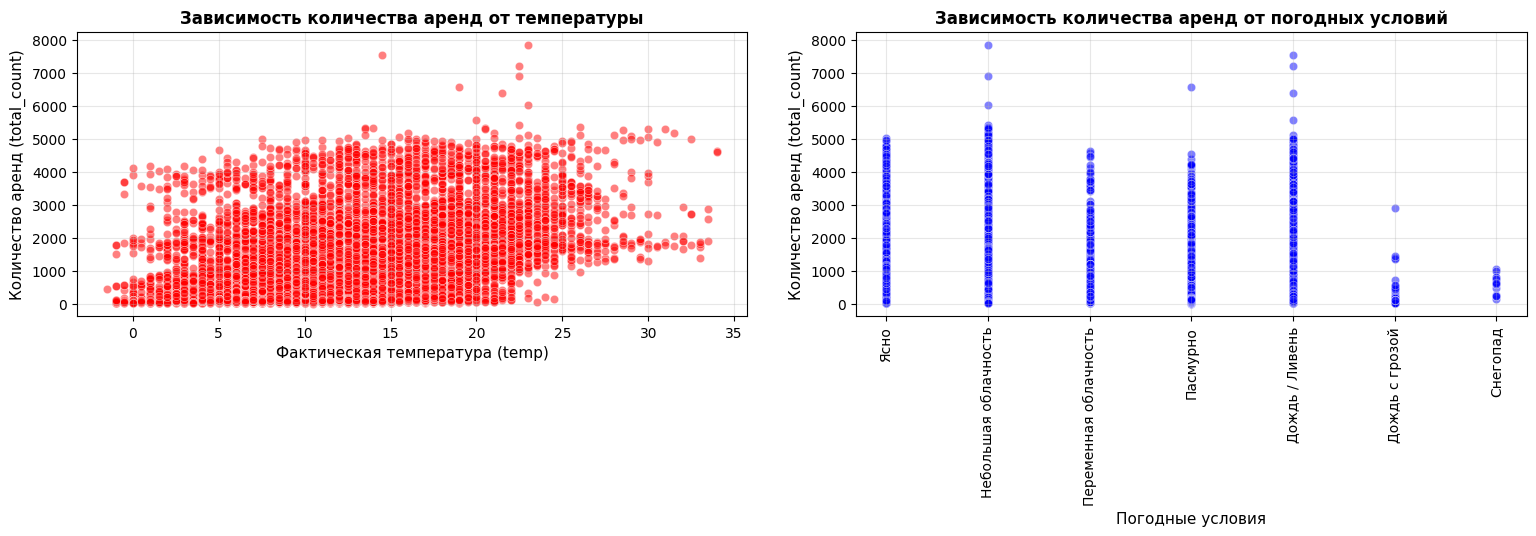

In [ ]:
# Напиши здесь код для двух scatter plot

weather_mapping = {
    1: 'Ясно',
    2: 'Небольшая облачность',
    3: 'Переменная облачность',
    4: 'Пасмурно',
    7: 'Дождь / Ливень',
    10: 'Дождь с грозой',
    26: 'Снегопад',
    94: 'Туман'
}

bike['weather_name'] = bike['weather_code'].map(weather_mapping)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=bike, x='temp', y='total_count', alpha=0.5, color='red', ax=axes[0])
axes[0].set_title('Зависимость количества аренд от температуры', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Фактическая температура (temp)', fontsize=11)
axes[0].set_ylabel('Количество аренд (total_count)', fontsize=11)
axes[0].grid(True, alpha=0.3)

sns.scatterplot(data=bike, x='weather_name', y='total_count', alpha=0.5, color='blue', ax=axes[1])
axes[1].set_title('Зависимость количества аренд от погодных условий', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Погодные условия', fontsize=11)
axes[1].set_ylabel('Количество аренд (total_count)', fontsize=11)

unique_weather = [w for w in weather_mapping.values() if w in bike['weather_name'].unique()]
axes[1].set_xticklabels(unique_weather, rotation=90, ha='center', fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout(pad=3.0)
plt.show()



**Твой вывод**

- Температура: Наблюдается нелинейная зависимость с положительным трендом. При повышении температуры от 0 до 20–25 °C количество арендованных велосипедов заметно растет, формируя плотное облако точек в верхних значениях. Однако при высоких температурах (выше 30–35 °C) спрос начинает падать, так как кататься в сильную жару становится некомфортно.
- Погода: Максимальные пики проката сосредоточены в категориях «Ясно», «Небольшая облачность» и «Переменная облачность». В пасмурную погоду или во время дождя плотность и максимум точек заметно снижаются. При неблагоприятных условиях вроде грозы или снегопада зафиксированы лишь единичные случаи аренды с минимальным количеством велосипедов.

###Задача 4.2 [2 балла]

In [ ]:
# Прежде чем перейти к следующему шагу — немного подправь данные
# Cтандартизация через StandardScaler

from sklearn.preprocessing import StandardScaler

# Возьми только числовые признаки
numerical_features = bike[['total_count', 'temp', 'feel_temp', 'humidity', 'wind_speed']]

# Инициализируй скейлер
scaler = StandardScaler()

# Примени его к числовым признакам
df_scaled = scaler.fit_transform(numerical_features)

# Переведи результат обратно в DataFrame
df_scaled = pd.DataFrame(df_scaled, columns=['total_count', 'temp', 'feel_temp', 'humidity', 'wind_speed'])





Создай финальный график.

1. Сделай расчёт корреляционной матрицы для датафрейма `df_scaled`. Построй тепловую карту (`heatmap`) этой матрицы с отображением значений корреляций, используй цветовую палитру `coolwarm`. Добавь заголовок и отобрази график.

2. Напиши подробный вывод по получившейся матрице. В первую очередь нас интересует, с чем коррелирует целевая переменная `total_count` и наибольшие значения положительной и отрицательной корреляции в матрице. Напиши минимум три пункта, которые вызывают интерес и могут быть полезны для решения задачи.



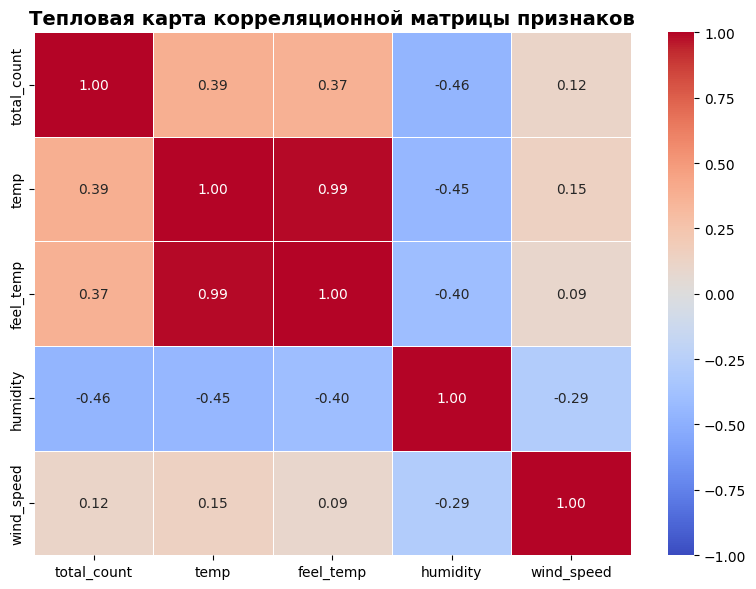

In [ ]:
# Напиши код здесь — матрица корреляции

corr_matrix = df_scaled.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, vmin=-1, vmax=1)

plt.title('Тепловая карта корреляционной матрицы признаков', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Твой вывод**

- Связь с целевой переменной: Целевая переменная имеет умеренную положительную корреляцию с температурой воздуха (temp и feel_temp, около 0.39) и заметную отрицательную корреляцию с влажностью (humidity, около -0.46). Это говорит о том, что люди намного охотнее берут велосипеды в теплую и сухую погоду. Скорость ветра (wind_speed) практически не влияет на спрос (корреляция близка к нулю).
- Проблема мультиколлинеарности: Между признаками temp (фактическая температура) и feel_temp (температура по ощущениям) наблюдается сильнейшая положительная корреляция (около 0.99). Это логично, но для линейных моделей машинного обучения представляет опасность (мультиколлинеарность). Один из этих признаков в будущем, возможно, придется удалить, чтобы не переобучить модель.
- Взаимосвязь погоды: Между влажностью (humidity) и температурой есть отрицательная связь. Высокая влажность часто сопутствует дождливой или холодной погоде, что дополнительно снижает целевой показатель total_count.

## Задача 5 [3 балла]

В задаче 5 ты полностью подготовишь данные для подачи в модель: выполнишь нормализацию признаков и разделишь данные на обучающую и тестовую выборки.  

1. Обучи любую модель регрессии из библиотеки `scikit-learn`.
2. Реализуй собственные функции для расчёта коэффициента детерминации (R²) и среднеквадратичной ошибки (MSE). **[1 балл]**
3. Вычисли значения метрик с помощью своих функций и сравни их с результатами расчёта с использованием функций из `scikit-learn` (должны получиться одинаковыми).
4. Составь краткий вывод по метрикам: какие значения получились и как их можно интерпретировать с точки зрения качества модели. **[2 балла]**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
X = bike.drop(['total_count','timestamp'], axis=1)
y = bike['total_count']

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = pd.concat(
    [
        pd.DataFrame(
            scaler.fit_transform(X_train[['temp', 'feel_temp', 'humidity', 'wind_speed']]),
            columns=['temp', 'feel_temp', 'humidity', 'wind_speed']
        ).reset_index(drop=True),
        X_train[['weather_code', 'is_holiday', 'is_weekend', 'season', 'year', 'month','day','day_of_week','hour']].reset_index(drop=True)
    ],
    axis=1
)
X_test_scaled = pd.concat(
    [
        pd.DataFrame(
            scaler.transform(X_test[['temp', 'feel_temp', 'humidity', 'wind_speed']]),
            columns=['temp', 'feel_temp', 'humidity', 'wind_speed']
        ).reset_index(drop=True),
        X_test[['weather_code', 'is_holiday', 'is_weekend', 'season', 'year', 'month','day','day_of_week','hour']].reset_index(drop=True)
    ],
    axis=1
)

In [ ]:
# Напиши здесь код для модели, метрик и валидации
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X_train_scaled = X_train_scaled.dropna()
X_test_scaled = X_test_scaled.dropna()

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

mse_sklearn = mean_squared_error(y_test, y_pred)
r2_sklearn = r2_score(y_test, y_pred)

mse_manual = np.mean((y_test - y_pred) ** 2)
r2_manual = 1 - (np.sum((y_test - y_pred) ** 2) / np.sum((y_test - np.mean(y_test)) ** 2))

print(f"MSE (scikit-learn): {mse_sklearn:.4f}")
print(f"MSE (вручную):      {mse_manual:.4f}")
print(f"R2 (scikit-learn):  {r2_sklearn:.4f}")
print(f"R2 (вручную):       {r2_manual:.4f}")


MSE (scikit-learn): 851079.8526
MSE (вручную):      851079.8526
R2 (scikit-learn):  0.2897
R2 (вручную):       0.2897


**Твой вывод**

- MSE: Значения, посчитанные вручную и через библиотеку scikit-learn, получились абсолютно идентичными. Метрика отражает средний квадрат ошибки предсказания модели. Поскольку целевая переменная выражена в абсолютном количестве велосипедов, извлечение корня из MSE (RMSE) покажет среднюю ошибку модели в реальных единицах (велосипедах).
- R2: Значения из библиотеки и ручного расчета также совпали. Коэффициент R2 показывает долю дисперсии целевой переменной, которую объясняет модель. Полученное значение говорит о том, что модель улавливает основные тренды, но её текущее качество является посредственным.
- Интерпретация качества: Модель обладает предсказательной силой, которая лучше простого константного предсказания, так как R2 > 0. Тем не менее, базовая линейная регрессия не может полностью учесть сложные нелинейные зависимости (например, падение спроса в пиковую жару) и суточные циклы, поэтому для улучшения качества в будущем стоит применить более сложные модели(градиентный бустинг возможно?).
